In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("CodeAlpha_Sales_Data.csv")

In [6]:
df.head()

,Order_ID,Date,Category,Product,Region,Quantity,Sales,Discount,Profit
0,1001,2026-01-05,Electronics,Laptop,South,2,1200,0.05,180
1,1002,2026-01-08,Furniture,Office Chair,North,1,250,0.10,35
2,1003,2026-01-15,Clothing,Jacket,East,3,180,0.00,54
3,1004,2026-01-20,Electronics,Headphones,West,2,300,0.15,45
4,1005,2026-02-03,Clothing,Shoes,South,4,220,0.05,44


In [7]:
df.shape


(15, 9)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  15 non-null     int64  
 1   Date      15 non-null     str    
 2   Category  15 non-null     str    
 3   Product   15 non-null     str    
 4   Region    15 non-null     str    
 5   Quantity  15 non-null     int64  
 6   Sales     15 non-null     int64  
 7   Discount  15 non-null     float64
 8   Profit    15 non-null     int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 1.2 KB


In [9]:
df.isnull().sum()

Order_ID    0
Date        0
Category    0
Product     0
Region      0
Quantity    0
Sales       0
Discount    0
Profit      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,Order_ID,Quantity,Sales,Discount,Profit
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,1008.000000,2.200000,391.000000,0.076667,60.533333
std,4.472136,1.207122,278.722853,0.059362,37.240275
min,1001.000000,1.000000,125.000000,0.000000,25.000000
25%,1004.500000,1.000000,215.000000,0.050000,43.000000
50%,1008.000000,2.000000,300.000000,0.050000,50.000000
75%,1011.500000,3.000000,475.000000,0.100000,66.500000
max,1015.000000,5.000000,1200.000000,0.200000,180.000000


In [12]:
df["Category"].unique()

<StringArray>
['Electronics', 'Furniture', 'Clothing']
Length: 3, dtype: str

In [13]:
df["Category"].value_counts()


Category
Electronics    5
Furniture      5
Clothing       5
Name: count, dtype: int64

In [14]:
df["Region"].value_counts()


Region
South    4
North    4
East     4
West     3
Name: count, dtype: int64

In [15]:
df["Product"].value_counts()

Product
Laptop          1
Office Chair    1
Jacket          1
Headphones      1
Shoes           1
Desk            1
Monitor         1
T-Shirt         1
Bookshelf       1
Keyboard        1
Jeans           1
Table           1
Tablet          1
Dress           1
Sofa            1
Name: count, dtype: int64

In [16]:
df.groupby("Category")["Sales"].sum()

Category
Clothing        955
Electronics    2690
Furniture      2220
Name: Sales, dtype: int64

In [17]:
df.groupby("Category")["Profit"].sum()

Category
Clothing       209
Electronics    433
Furniture      266
Name: Profit, dtype: int64

In [18]:
df.groupby("Region")["Profit"].sum()

Region
East     232
North    194
South    362
West     120
Name: Profit, dtype: int64

In [19]:
df.groupby("Region")[["Sales","Profit"]].sum()

,Sales,Profit
Region,,
East,1420,232
North,1180,194
South,2340,362
West,925,120


In [20]:
df.groupby("Product")["Profit"].sum().sort_values(ascending=False)
                            

Product
Laptop          180
Tablet           90
Monitor          76
Sofa             70
Desk             63
Dress            54
Jacket           54
Table            50
Bookshelf        48
Headphones       45
Shoes            44
Keyboard         42
Office Chair     35
Jeans            32
T-Shirt          25
Name: Profit, dtype: int64

In [21]:
df.groupby("Sales")["Profit"].sum().sort_values(ascending=False)

Sales
1200    180
600      90
380      76
700      70
450      63
270      54
180      54
500      50
320      48
300      45
220      44
210      42
250      35
160      32
125      25
Name: Profit, dtype: int64

In [22]:
df.groupby("Region")[["Sales","Profit"]].sum()

,Sales,Profit
Region,,
East,1420,232
North,1180,194
South,2340,362
West,925,120


In [23]:
df.groupby("Category")[["Sales","Profit"]].sum()

,Sales,Profit
Category,,
Clothing,955,209
Electronics,2690,433
Furniture,2220,266


In [24]:
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100
df[["Product","Sales","Profit","Profit_Margin"]]

,Product,Sales,Profit,Profit_Margin
0,Laptop,1200,180,15.0
1,Office Chair,250,35,14.0
2,Jacket,180,54,30.0
3,Headphones,300,45,15.0
4,Shoes,220,44,20.0
5,Desk,450,63,14.0
6,Monitor,380,76,20.0
7,T-Shirt,125,25,20.0
8,Bookshelf,320,48,15.0
9,Keyboard,210,42,20.0


In [31]:
df[["Product", "Sales", "Profit", "Profit_Margin"]].sort_values("Profit_Margin",ascending=False)


,Product,Sales,Profit,Profit_Margin
2,Jacket,180,54,30.0
6,Monitor,380,76,20.0
4,Shoes,220,44,20.0
13,Dress,270,54,20.0
10,Jeans,160,32,20.0
9,Keyboard,210,42,20.0
7,T-Shirt,125,25,20.0
8,Bookshelf,320,48,15.0
12,Tablet,600,90,15.0
0,Laptop,1200,180,15.0


In [33]:
df[df["Profit_Margin"] > 20]

,Order_ID,Date,Category,Product,Region,Quantity,Sales,Discount,Profit,Profit_Margin
2,1003,2026-01-15,Clothing,Jacket,East,3,180,0.0,54,30.0


<Axes: xlabel='Category'>

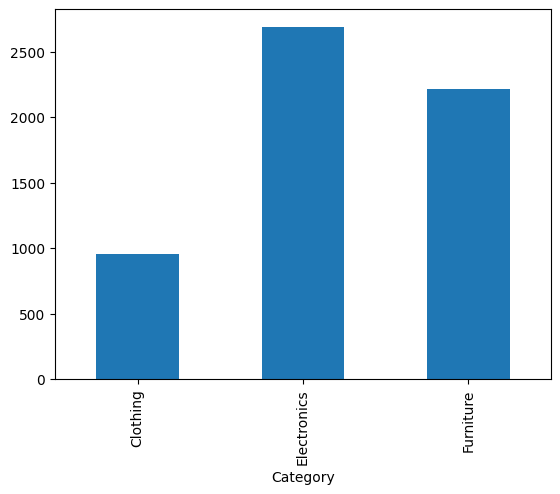

In [35]:
df.groupby("Category")["Sales"].sum().plot(kind="bar")

<Axes: xlabel='Category'>

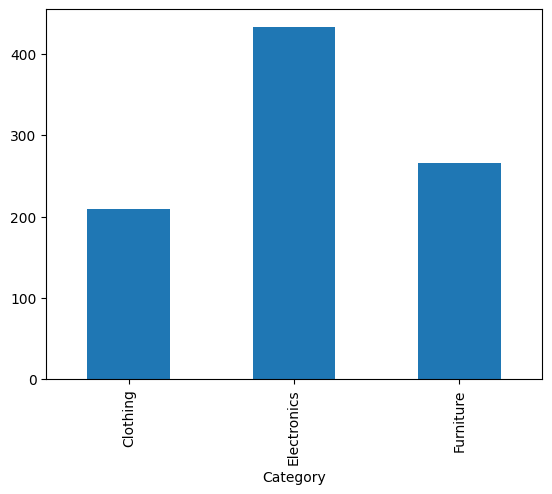

In [36]:
df.groupby("Category")["Profit"].sum().plot(kind="bar")

<Axes: xlabel='Region'>

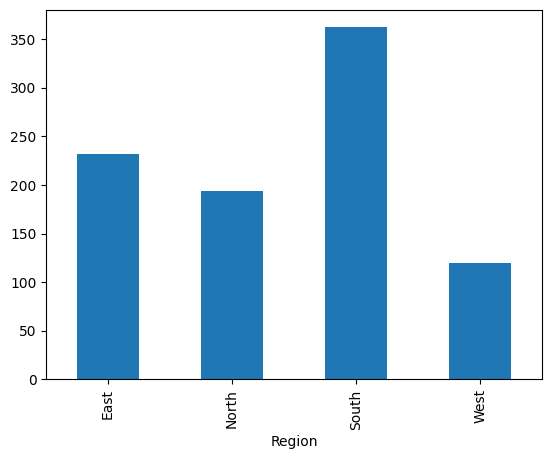

In [37]:
df.groupby("Region")["Profit"].sum().plot(kind="bar")

<Axes: xlabel='Region'>

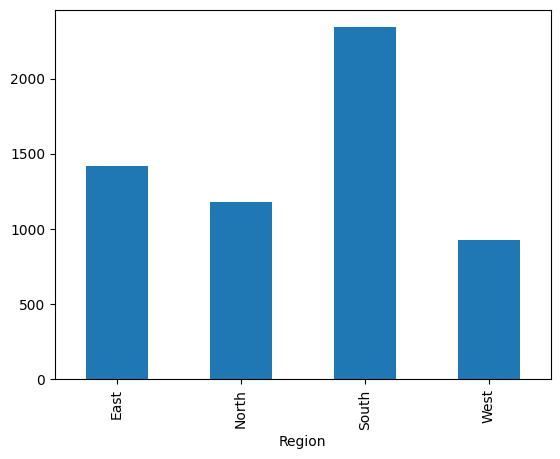

In [38]:
df.groupby("Region")["Sales"].sum().plot(kind="bar")

<Axes: xlabel='Product'>

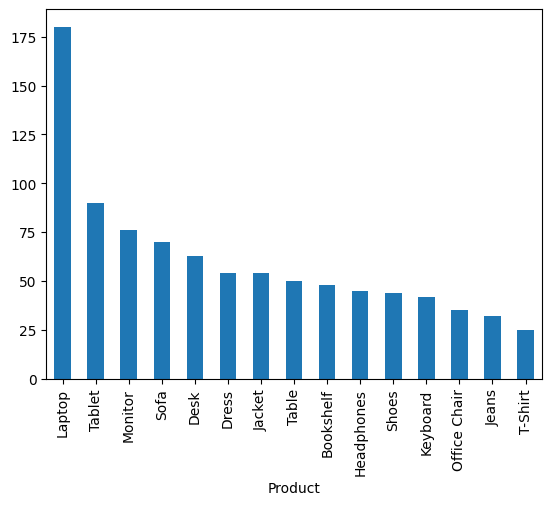

In [39]:
df.groupby("Product")["Profit"].sum().sort_values(ascending=False).plot(kind="bar")

<Axes: xlabel='Sales', ylabel='Profit'>

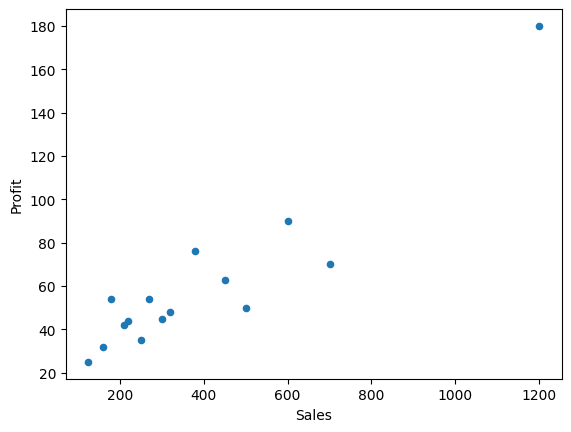

In [42]:
df.plot(kind="scatter",x="Sales",y="Profit")

In [44]:
df["Date"]=pd.to_datetime(df["Date"])

In [49]:
df.groupby(df["Date"].dt.to_period("M"))["Sales"].sum()

Date
2026-01    1930
2026-02    1175
2026-03    1190
2026-04    1570
Freq: M, Name: Sales, dtype: int64

<Axes: xlabel='Date'>

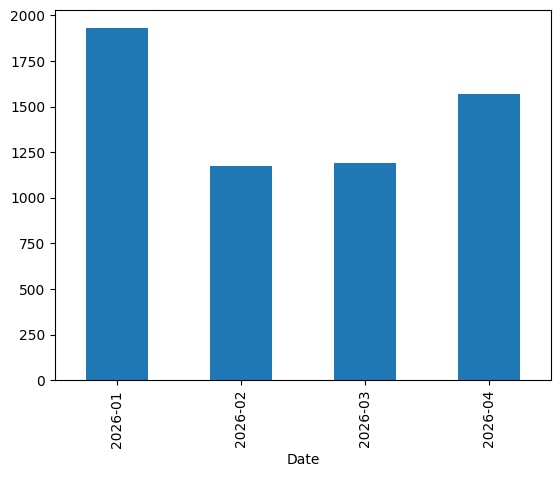

In [50]:
df.groupby(df["Date"].dt.to_period("M"))["Sales"].sum().plot(kind="bar")

In [51]:
df.loc[df["Profit_Margin"].idxmax()]

Order_ID                        1003
Date             2026-01-15 00:00:00
Category                    Clothing
Product                       Jacket
Region                          East
Quantity                           3
Sales                            180
Discount                         0.0
Profit                            54
Profit_Margin                   30.0
Name: 2, dtype: object

In [52]:
df.loc[df["Sales"].idxmax()]

Order_ID                        1001
Date             2026-01-05 00:00:00
Category                 Electronics
Product                       Laptop
Region                         South
Quantity                           2
Sales                           1200
Discount                        0.05
Profit                           180
Profit_Margin                   15.0
Name: 0, dtype: object

In [53]:
df[["Sales", "Profit"]].sum()

Sales     5865
Profit     908
dtype: int64

In [54]:
df[["Sales", "Profit"]].mean()

Sales     391.000000
Profit     60.533333
dtype: float64

In [55]:
df[["Sales", "Profit"]].sum()

Sales     5865
Profit     908
dtype: int64

In [56]:
df[["Sales", "Profit"]].mean()

Sales     391.000000
Profit     60.533333
dtype: float64

In [ ]:
## Key Findings

- Electronics category has the highest sales and profit.
- South region has the highest sales and profit.
- Laptop has the highest sales among all products.
- Jacket has the highest profit margin.
- January has the highest monthly sales.
- The dataset contains no missing values.
- The dataset contains no duplicate records.